# Imports

In [1]:
import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
from tqdm import tqdm
import subprocess

import os, sys, re
sys.path.append("D:\\DATA\\ActivePIC")
from pathlib import Path

rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit
import rsoft_lib as rlib

import importlib

# P-02: Side-step bend

In [ ]:
# Define directories and files to work with
device_name = "P-02_SideStepBend_geometry"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\P-02_SideStepBend\\"
CAD_path = f"{working_dir}{device_name}.ind"

bendRadius_arr = np.linspace(500, 800, 4)
design_wav = 1.55

print('Straight-to-bend offsets:')
# Save GDS files for each variation
for bendRadius in bendRadius_arr:
    bendRadius_str = f"{bendRadius:0.3f}".replace('.', 'p')
    offset = abs(rlib.straight_offset(bendRadius, design_wav))

    c = RSoftCircuit()
    c.read(CAD_path)
    c.set_symbol("bendRadius", bendRadius)
    c.set_symbol("Straight_offset", offset)
    c.write(CAD_path)

    print(f'Radius μm = {bendRadius}: {offset} μm")

    rlib.ind2gds(CAD_path, gds_path=f"{working_dir}{device_name}_bendRadius{bendRadius_str}.gds")

0.4664057795330245
0.37811049045291256
0.3167363216536327
0.2727472931990317


# P-03: Radiation witness

In [3]:
filename_root = 'P-03_RadiationWitness'
variants = ['P-03a_RadiationWitness_circular', 'P-03b_RadiationWitness_euler', 'P-03ref_RadiationWitness_reference']
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{filename_root}\\"

# Save GDS files for each variation
for variation in variants:
    CAD_path = f"{working_dir}{variation}.ind"
    rlib.ind2gds(CAD_path, gds_path=f"{working_dir}{variation}.gds", cwd=working_dir)

# P-05: Unbalanced MZI

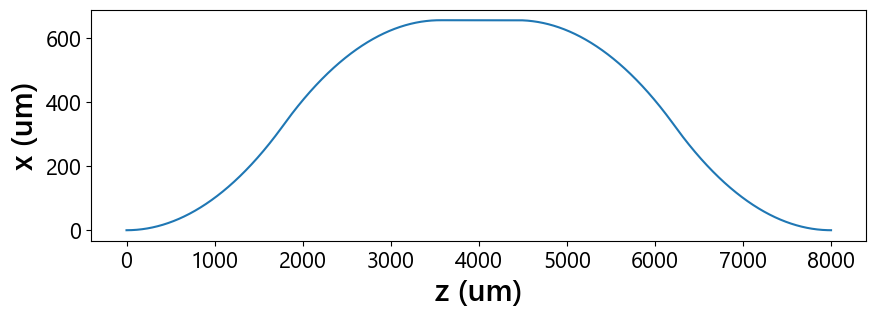

Length bum - reference:  159.9999878708968 μm


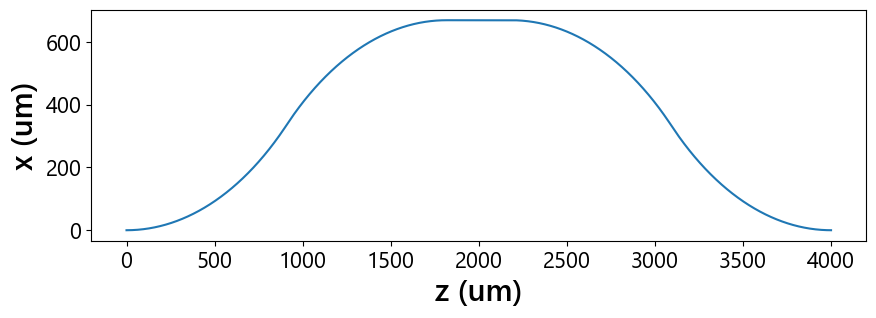

Length bum - reference:  319.9999161464266 μm


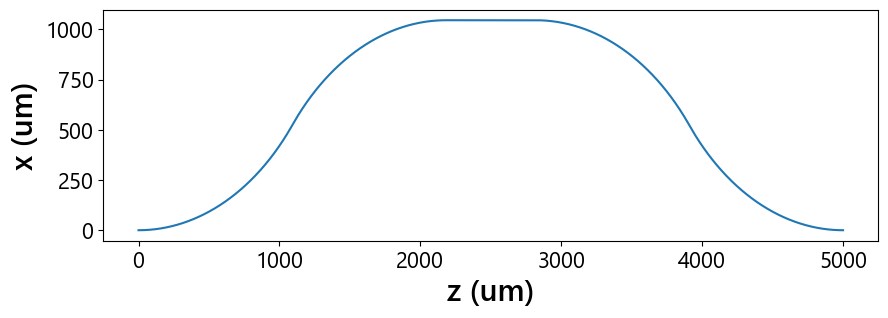

Length bum - reference:  639.9998937641749 μm


In [ ]:
filename_root = 'P-05_UnbalancedMZI'
variants = ['P-05a_UnbalancedMZI', 'P-05b_UnbalancedMZI', 'P-05c_UnbalancedMZI']
parameters = [(8000, 160, 5000), (4000, 320, 1400), (5000, 640, 1400)]
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{filename_root}\\"

# Save GDS files for each variation
for i, variant in enumerate(variants):
    z_length, deltaL, R = parameters[i]
    x, z, phi = rlib.delay_arm(z_length, deltaL, R, end_straight=0, ds=1.0, x0=0.0, direction=1, plot=True)
    s, curvature = rlib.bend_curvature(x, z, phi)
    print('Length bump - reference: ', s[-1] - z_length, 'μm')
    rlib.save_gds(f"{working_dir}{variant}_bump.gds", x, z, phi, width=3.4, layer=1)

# P-06: Bend-phase MZI

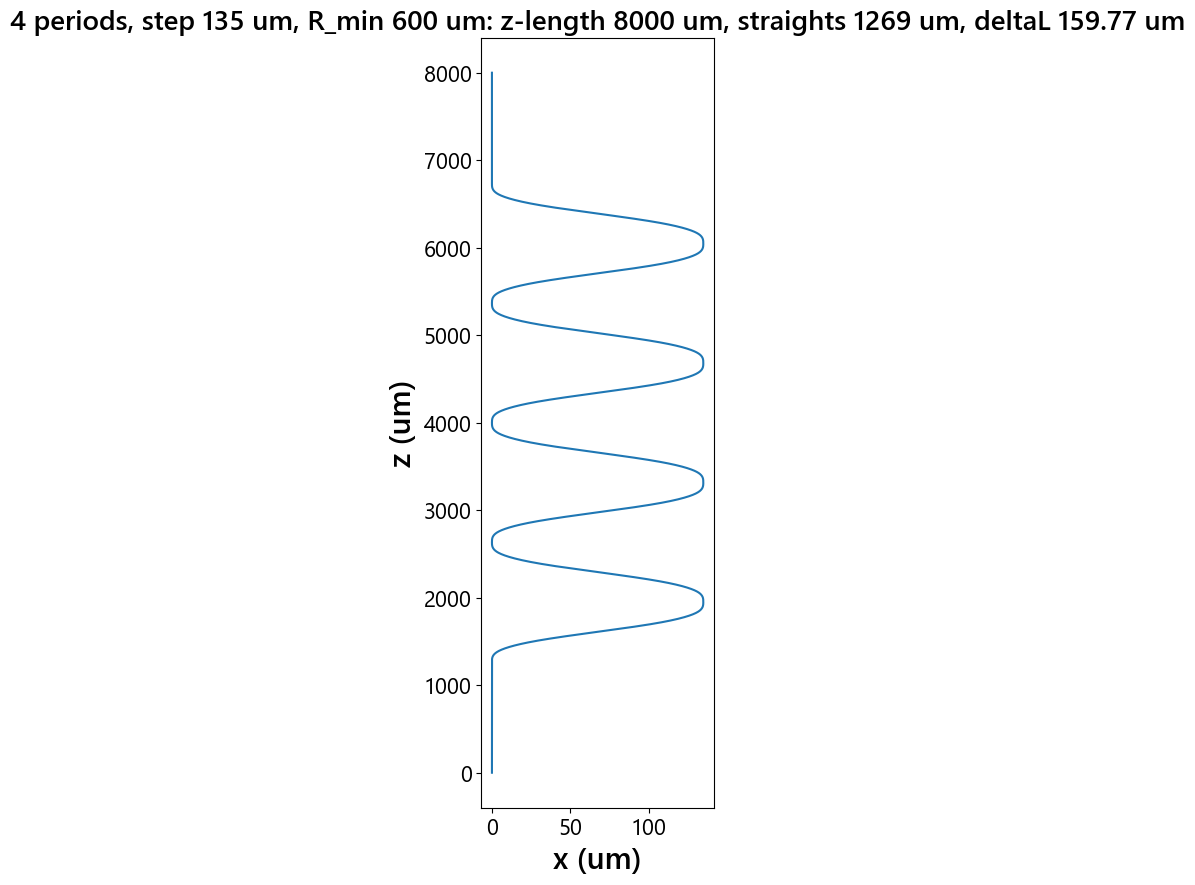

Length wave - reference:  159.76742439796635 μm


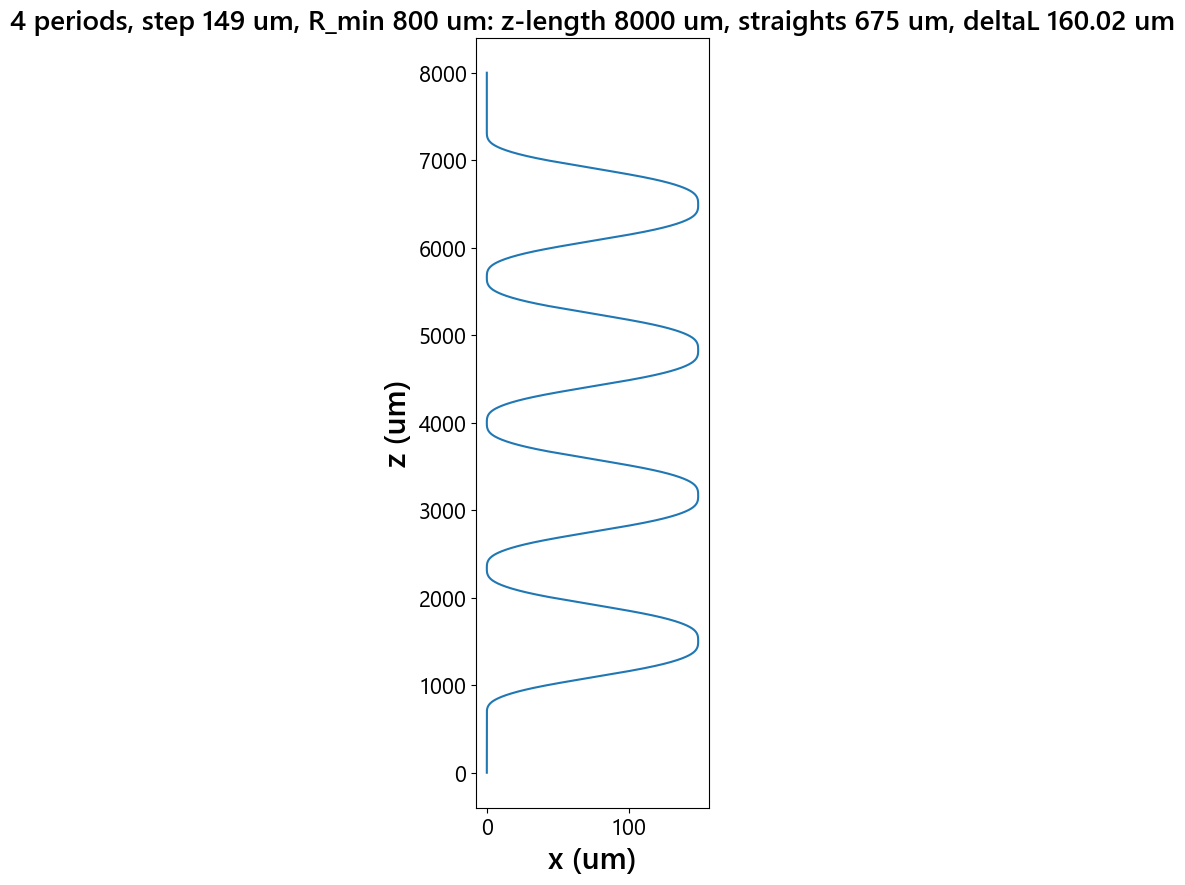

Length wave - reference:  160.02264643798117 μm


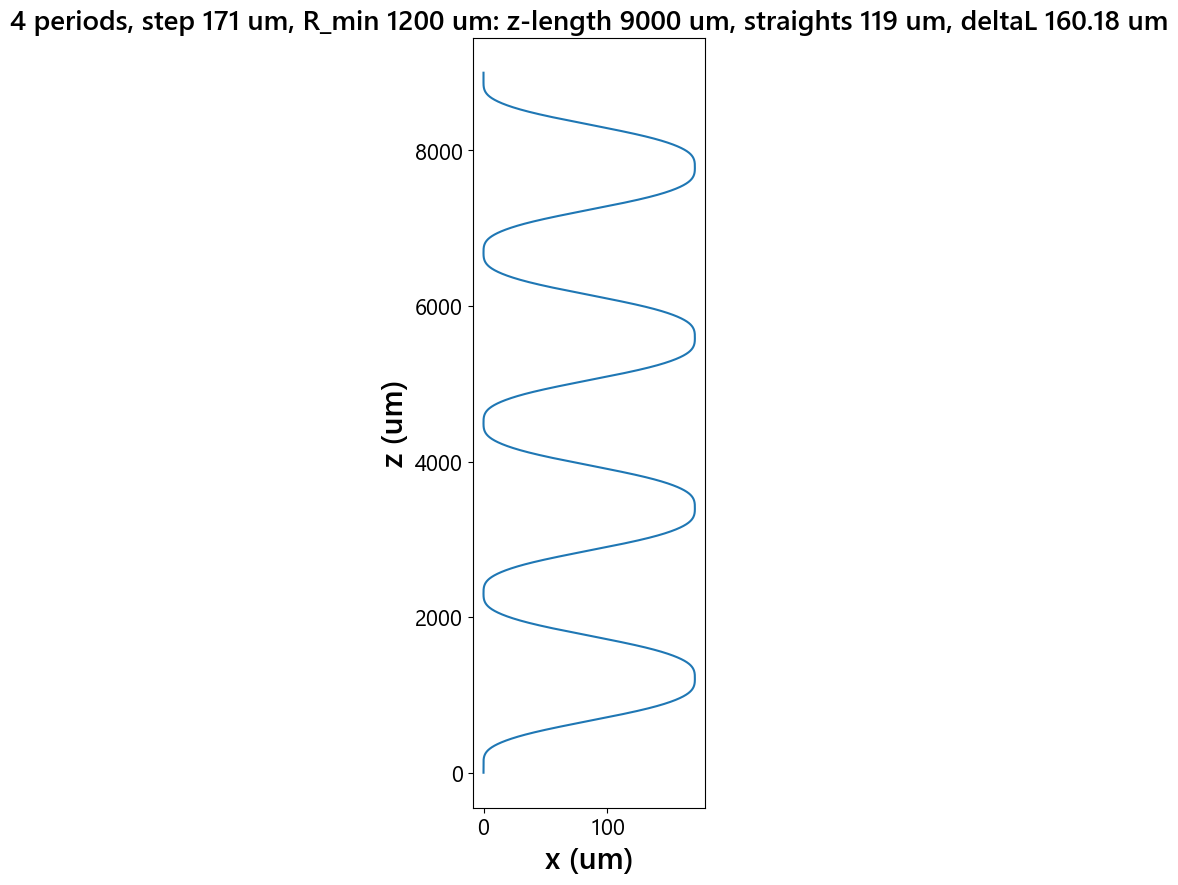

Length wave - reference:  160.17659463330892 μm


In [6]:
filename_root = 'P-06_BendPhaseMZI'
variants = ['P-06a_BendPhaseMZI', 'P-06b_BendPhaseMZI', 'P-06c_BendPhaseMZI']
parameters = [(4, 135, 600, 8000), (4, 149, 800, 8000), (4, 171, 1200, 9000)]
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{filename_root}\\"

# Save GDS files for each variation
for i, variant in enumerate(variants):
    n_periods, step, R_min, z_length = parameters[i]
    x, z, phi, info = rlib.euler_wave(n_periods, step, R_min, z_length=z_length, p=0.5, return_params=True, plot=True)
    s, curvature = rlib.bend_curvature(x, z, phi)
    print('Length wave - reference: ', s[-1] - z_length, 'μm')
    rlib.save_gds(f"{working_dir}{variant}_wave.gds", x, z, phi, width=3.4, layer=1)

# P-07: Width MZI

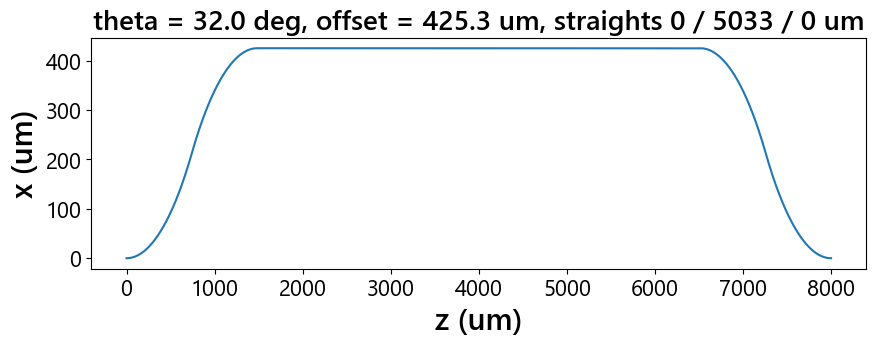

Length bump - reference:  159.99993356143386 μm


In [11]:
filename_root = 'P-07_WidthMZI'
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{filename_root}\\"

z_length, deltaL, R = 8000, 160, 1400
x, z, phi = rlib.delay_arm(z_length, deltaL, R, end_straight=0, ds=1.0, x0=0.0, direction=1, plot=True)
s, curvature = rlib.bend_curvature(x, z, phi)
print('Length bump - reference: ', s[-1] - z_length, 'μm')
rlib.save_gds(f"{working_dir}{filename_root}_bump.gds", x, z, phi, width=3.4, layer=1)

# P-10: APD MZI

D:\DATA\ActivePIC\rsoft_lib\geometry.py:279: UserWarning: The middle straight is only 367.9 um long: the two S-bends already take 3632.1 um of the 4000 um z-length (theta = 40.4 deg, offset 668.8 um). A longer z_length or a smaller R leaves more room.
  warnings.warn(f"The middle straight is only {L_mid:.1f} um long: the two S-bends already take {4 * R * np.sin(theta):.1f} um "


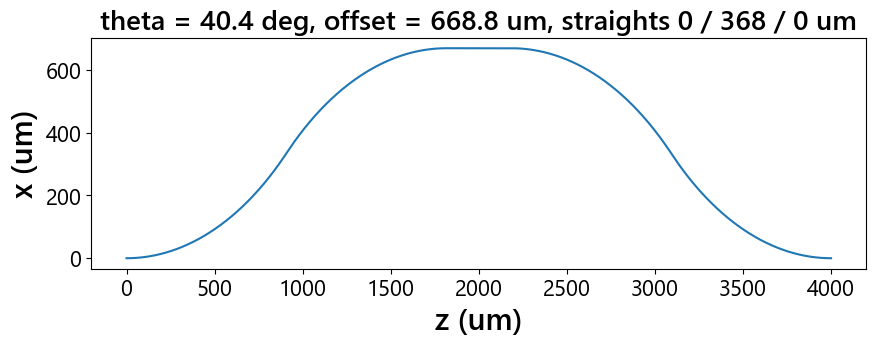

Length bump - reference:  319.9999161464266 μm


In [10]:
filename_root = 'P-10_APDMZI'
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{filename_root}\\"

z_length, deltaL, R = 4000, 320, 1400
x, z, phi = rlib.delay_arm(z_length, deltaL, R, end_straight=0, ds=1.0, x0=0.0, direction=1, plot=True)
s, curvature = rlib.bend_curvature(x, z, phi)
print('Length bump - reference: ', s[-1] - z_length, 'μm')
rlib.save_gds(f"{working_dir}{variant}_bump.gds", x, z, phi, width=3.4, layer=1)